In [2]:
import numpy as np

def neuron(inputs, weights):
    score = np.dot(inputs, weights)          # guna karke jodna
    prob = 1 / (1 + np.exp(-score))          # sigmoid
    return score, prob

inputs  = np.array([3, 1])      # free, links
weights = np.array([2, -10])

score, prob = neuron(inputs, weights)
print("score:", score)
print("probability:", round(prob, 4))

score: -4
probability: 0.018


In [3]:
w = 0.0
x, target = 2, 6
lr = 0.1                      # ek baar mein kitna badalna (learning rate)

for step in range(8):
    pred  = w * x
    error = pred - target
    w = w - lr * error * x    # weight ko error ke hisaab se badlo
    print(step, "w =", round(w, 3), "| error =", round(error, 3))

0 w = 1.2 | error = -6.0
1 w = 1.92 | error = -3.6
2 w = 2.352 | error = -2.16
3 w = 2.611 | error = -1.296
4 w = 2.767 | error = -0.778
5 w = 2.86 | error = -0.467
6 w = 2.916 | error = -0.28
7 w = 2.95 | error = -0.168


In [4]:
w = 0.0
x, target = 2, 6
lr = 0.6

for step in range(6):
    pred  = w * x
    error = pred - target
    w = w - lr * error * x
    print(step, "w =", round(w, 3), "| error =", round(error, 3))

0 w = 7.2 | error = -6.0
1 w = -2.88 | error = 8.4
2 w = 11.232 | error = -11.76
3 w = -8.525 | error = 16.464
4 w = 19.135 | error = -23.05
5 w = -19.589 | error = 32.269


In [5]:
w = 0.0
x, target = 2, 6
lr = 0.001

for step in range(8):
    pred  = w * x
    error = pred - target
    w = w - lr * error * x
    print(step, "w =", round(w, 4), "| error =", round(error, 3))

0 w = 0.012 | error = -6.0
1 w = 0.024 | error = -5.976
2 w = 0.0359 | error = -5.952
3 w = 0.0477 | error = -5.928
4 w = 0.0595 | error = -5.905
5 w = 0.0713 | error = -5.881
6 w = 0.083 | error = -5.857
7 w = 0.0947 | error = -5.834


In [6]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_val_score

np.random.seed(7)
n = 300
free     = np.random.randint(0, 8, n)
links    = np.random.randint(0, 6, n)
caps     = np.random.randint(0, 10, n)
exclaim  = np.random.randint(0, 6, n)
score = 1.0*free + 0.8*links + 0.5*caps + 0.6*exclaim + np.random.randn(n)*3
y = (score > np.percentile(score, 65)).astype(int)
X = np.column_stack([free, links, caps, exclaim])

models = {
    "Logistic": make_pipeline(StandardScaler(), LogisticRegression()),
    "Neural net (8,4)": make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(8, 4), max_iter=2000, random_state=0)),
}

for name, m in models.items():
    s = cross_val_score(m, X, y, cv=5, scoring="f1")
    print(name, "| F1 avg:", s.mean().round(2), "| spread:", s.min().round(2), "-", s.max().round(2))

Logistic | F1 avg: 0.66 | spread: 0.59 - 0.76
Neural net (8,4) | F1 avg: 0.7 | spread: 0.65 - 0.78


(5, 5)


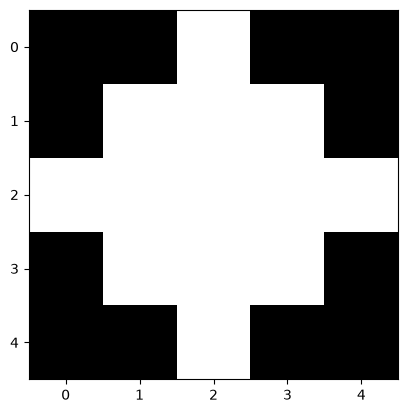

In [7]:
import numpy as np
import matplotlib.pyplot as plt

img = np.array([
    [  0,   0, 255,   0,   0],
    [  0, 255, 255, 255,   0],
    [255, 255, 255, 255, 255],
    [  0, 255, 255, 255,   0],
    [  0,   0, 255,   0,   0],
])

print(img.shape)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.show()

In [8]:
import numpy as np

img = np.array([[0, 0, 0, 255, 255, 255]] * 6)
filt = np.array([[-1, 0, 1],
                 [-1, 0, 1],
                 [-1, 0, 1]])

out = np.zeros((4, 4))
for i in range(4):
    for j in range(4):
        patch = img[i:i+3, j:j+3]
        out[i, j] = np.sum(patch * filt)

print(out)

[[  0. 765. 765.   0.]
 [  0. 765. 765.   0.]
 [  0. 765. 765.   0.]
 [  0. 765. 765.   0.]]
